# TinyLlama Instruction Fine-Tuning with LoRA

Executed Colab notebook with explanatory notes. Original code cells, execution counts and saved outputs are preserved from `Untitled11.ipynb`; only Markdown notes have been added or completed. Results below are read from the supplied execution record, not a new run.

**Summary:** 0.2044% trainable parameters; validation loss 1.8756 → 1.3242; adapter weights 8.62 MiB. Response quality improved on some examples but regressed on others.

## 1. Environment verification

This cell records the actual installed package versions and checks imports. The saved output reports dependency conflicts, although the training-library imports and subsequent training completed. This is not a clean dependency check. For a fresh Colab session, use the repository requirements and the setup guidance in the README; the historical output is retained unchanged.

In [1]:
import subprocess
import sys
from importlib.metadata import version

result = subprocess.run(
    [sys.executable, "-m", "pip", "check"],
    capture_output=True,
    text=True,
)

print(result.stdout or result.stderr)

from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import LoraConfig, get_peft_model
from trl import SFTConfig, SFTTrainer
from datasets import load_dataset

for package in [
    "pandas", "huggingface-hub", "fsspec",
    "transformers", "trl", "peft", "datasets",
]:
    print(f"{package}: {version(package)}")

print("\nTraining-library imports passed.")

ipython 7.34.0 requires jedi, which is not installed.
google-colab 1.0.0 has requirement pandas==2.2.3, but you have pandas 2.3.3.
gradio 6.30.0 has requirement huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2.
gradio-client 2.7.2 has requirement huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2.
diffusers 0.42.0 has requirement huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2.
gcsfs 2025.12.0 has requirement fsspec==2025.12.0, but you have fsspec 2025.10.0.

pandas: 2.3.3
huggingface-hub: 0.36.2
fsspec: 2025.10.0
transformers: 4.57.3
trl: 0.26.0
peft: 0.18.0
datasets: 4.4.1

Training-library imports passed.


## 2. Runtime and reproducibility

The recorded run used a Tesla T4 and PyTorch 2.11.0+cu130. The seed is 42, and model/dataset revision hashes are printed and saved in the training metrics. Public model downloads succeeded without an HF_TOKEN. The code resolves current revisions on rerun; use the recorded hashes to reproduce the same source versions.

In [2]:
import gc
import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import torch

from datasets import load_dataset
from huggingface_hub import model_info, dataset_info
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    set_seed,
)
from peft import LoraConfig, TaskType, get_peft_model, PeftModel
from trl import SFTConfig, SFTTrainer
from IPython.display import display

assert torch.cuda.is_available(), (
    "Enable a GPU: Runtime → Change runtime type → T4 GPU"
)

SEED = 42
set_seed(SEED)

MODEL_ID = "TinyLlama/TinyLlama-1.1B-Chat-v1.0"
DATASET_ID = "databricks/databricks-dolly-15k"

MODEL_REVISION = model_info(MODEL_ID).sha
DATASET_REVISION = dataset_info(DATASET_ID).sha

MAX_LENGTH = 512
SYSTEM_PROMPT = "You are a helpful assistant. Follow the user instructions."

OUTPUT_DIR = Path("/content/lora_results")
OUTPUT_DIR.mkdir(exist_ok=True)

print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)
print("Model revision:", MODEL_REVISION)
print("Dataset revision:", DATASET_REVISION)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


GPU: Tesla T4
PyTorch: 2.11.0+cu130
Model revision: fe8a4ea1ffedaf415f4da2f062534de366a451e6
Dataset revision: bdd27f4d94b9c1f951818a7da7fd7aeea5dbff1a


## 3. Load the frozen backbone

TinyLlama-1.1B-Chat contains 1,100,048,384 base parameters. FP16 loading reduces weight memory. Its existing chat template is used consistently for training and inference. Padding uses the EOS token; the trainer masks padding from the loss.

In [3]:
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    revision=MODEL_REVISION,
)

tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"

assert tokenizer.chat_template is not None

base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    revision=MODEL_REVISION,
    torch_dtype=torch.float16,
    attn_implementation="sdpa",
).to("cuda")

print("Base model loaded.")
print(f"Base parameters: {sum(p.numel() for p in base_model.parameters()):,}")

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/500k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/551 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/608 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/2.20G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Base model loaded.
Base parameters: 1,100,048,384


## 4. Prepare instruction-response conversations

Each example becomes system, user and assistant messages. Optional context is appended to the instruction under a Context label. Assertions check examples with and without context. The recorded dataset contains 15,011 non-empty examples.

In [4]:
raw_dataset = load_dataset(
    DATASET_ID,
    revision=DATASET_REVISION,
    split="train",
)

def format_example(example):
    instruction = (example.get("instruction") or "").strip()
    context = (example.get("context") or "").strip()
    response = (example.get("response") or "").strip()

    user_message = instruction

    if context:
        user_message += "\n\nContext:\n" + context

    return {
        "messages": [
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": user_message},
            {"role": "assistant", "content": response},
        ]
    }

# Verify both formatting cases.
without_context = format_example({
    "instruction": "Answer the question.",
    "context": "",
    "response": "An answer.",
})

with_context = format_example({
    "instruction": "Summarize this.",
    "context": "LoRA trains a small set of adapter parameters.",
    "response": "LoRA trains small adapters.",
})

assert without_context["messages"][1]["content"] == "Answer the question."
assert with_context["messages"][1]["content"] == (
    "Summarize this.\n\nContext:\n"
    "LoRA trains a small set of adapter parameters."
)

raw_dataset = raw_dataset.filter(
    lambda row: bool((row["instruction"] or "").strip())
    and bool((row["response"] or "").strip())
)

formatted_dataset = raw_dataset.map(
    format_example,
    remove_columns=raw_dataset.column_names,
)

print(json.dumps(with_context, indent=2))
print("Formatted examples:", len(formatted_dataset))

README.md: 0.00B [00:00, ?B/s]

databricks-dolly-15k.jsonl:   0%|          | 0.00/13.1M [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Filter:   0%|          | 0/15011 [00:00<?, ? examples/s]

Map:   0%|          | 0/15011 [00:00<?, ? examples/s]

{
  "messages": [
    {
      "role": "system",
      "content": "You are a helpful assistant. Follow the user instructions."
    },
    {
      "role": "user",
      "content": "Summarize this.\n\nContext:\nLoRA trains a small set of adapter parameters."
    },
    {
      "role": "assistant",
      "content": "LoRA trains small adapters."
    }
  ]
}
Formatted examples: 15011


## 5. Deduplicate, filter and split

Exact user-prompt deduplication leaves 14,824 examples. Filtering removes 1,306 conversations longer than 512 tokens. The tokenizer warning arises while measuring raw lengths, before the filter; those overlength examples are excluded from training. The experiment uses 3,000 training, 200 validation and 200 test examples. Filtering avoids truncating responses but biases the experiment toward shorter conversations. Prompt/completion pairs support response-only loss.

In [5]:
seen = set()
unique_indices = []

for index, row in enumerate(formatted_dataset):
    prompt = row["messages"][1]["content"]

    if prompt not in seen:
        seen.add(prompt)
        unique_indices.append(index)

formatted_dataset = formatted_dataset.select(unique_indices)

before_filter = len(formatted_dataset)

formatted_dataset = formatted_dataset.filter(
    lambda row: len(
        tokenizer.apply_chat_template(
            row["messages"],
            tokenize=True,
            add_generation_prompt=False,
        )
    ) <= MAX_LENGTH
)

print("Overlength examples removed:", before_filter - len(formatted_dataset))

assert len(formatted_dataset) >= 3400

split = formatted_dataset.train_test_split(
    test_size=400,
    seed=SEED,
)

heldout = split["test"].train_test_split(
    test_size=200,
    seed=SEED,
)

train_messages = (
    split["train"]
    .shuffle(seed=SEED)
    .select(range(3000))
)

validation_messages = heldout["train"]
test_messages = heldout["test"]

def to_prompt_completion(row):
    return {
        "prompt": row["messages"][:-1],
        "completion": row["messages"][-1:],
    }

train_dataset = train_messages.map(
    to_prompt_completion,
    remove_columns=["messages"],
)

validation_dataset = validation_messages.map(
    to_prompt_completion,
    remove_columns=["messages"],
)

print("Training examples:", len(train_dataset))
print("Validation examples:", len(validation_dataset))
print("Test examples:", len(test_messages))

print("\nRendered training conversation:\n")
print(
    tokenizer.apply_chat_template(
        train_messages[0]["messages"],
        tokenize=False,
        add_generation_prompt=False,
    )
)

Filter:   0%|          | 0/14824 [00:00<?, ? examples/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (2287 > 2048). Running this sequence through the model will result in indexing errors


Overlength examples removed: 1306


Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

Training examples: 3000
Validation examples: 200
Test examples: 200

Rendered training conversation:

<|system|>
You are a helpful assistant. Follow the user instructions.</s>
<|user|>
Which is a species of fish? Pitbull or Tuna</s>
<|assistant|>
Tuna</s>



## 6. Capture the baseline

Twenty fixed held-out prompts are evaluated before LoRA injection. Both versions use greedy decoding and a 192-token output cap. Some responses reach this cap, so completeness differences should be interpreted alongside the common generation limit. The baseline is already a chat model, making improvement an empirical question.

In [6]:
test_examples = [test_messages[i] for i in range(20)]

@torch.inference_mode()
def generate_response(model, messages):
    model.eval()

    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True,
    ).to("cuda")

    generated_ids = model.generate(
        **inputs,
        max_new_tokens=192,
        do_sample=False,
        use_cache=True,
        pad_token_id=tokenizer.pad_token_id,
        eos_token_id=tokenizer.eos_token_id,
    )

    new_tokens = generated_ids[0, inputs["input_ids"].shape[1]:]

    return tokenizer.decode(
        new_tokens,
        skip_special_tokens=True,
    )

baseline_responses = []

for index, example in enumerate(test_examples, start=1):
    response = generate_response(
        base_model,
        example["messages"][:-1],
    )

    baseline_responses.append(response)
    print(f"Baseline {index}/{len(test_examples)} completed")

with open(OUTPUT_DIR / "baseline.json", "w") as file:
    json.dump(baseline_responses, file, indent=2)

print("\nExample prompt:")
print(test_examples[0]["messages"][1]["content"])

print("\nBaseline response:")
print(baseline_responses[0])

Baseline 1/20 completed
Baseline 2/20 completed
Baseline 3/20 completed
Baseline 4/20 completed
Baseline 5/20 completed
Baseline 6/20 completed
Baseline 7/20 completed
Baseline 8/20 completed
Baseline 9/20 completed
Baseline 10/20 completed
Baseline 11/20 completed
Baseline 12/20 completed
Baseline 13/20 completed
Baseline 14/20 completed
Baseline 15/20 completed
Baseline 16/20 completed
Baseline 17/20 completed
Baseline 18/20 completed
Baseline 19/20 completed
Baseline 20/20 completed

Example prompt:
Why do Jewish holidays begin at sunset the night before?

Baseline response:
The Jewish holidays begin at sunset the night before because this is the time when the sun is at its highest point in the sky, which is also the time when the sun is most visible to the naked eye. This is also the time when the moon is at its fullest, which is why the Jewish calendar is based on lunar cycles. Therefore, the Jewish holidays begin at sunset the night before to ensure that the full moon is visible 

## 7. Configure LoRA and inspect trainable parameters

Rank 8 provides modest adapter capacity; alpha 16 gives scaling alpha/r = 2. Dropout 0.05 regularizes adaptation. Targeting q_proj, k_proj, v_proj and o_proj changes attention queries, keys, values and output mixing, while leaving the backbone frozen. The measured trainable count is 2,252,800 out of 1,102,301,184 total parameters, or 0.2044%. Trainable adapter weights remain FP32 for mixed-precision training.

In [7]:
target_modules = ["q_proj", "k_proj", "v_proj", "o_proj"]

for target in target_modules:
    assert any(
        name.endswith("." + target)
        for name, _ in base_model.named_modules()
    ), f"Missing target module: {target}"

lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    target_modules=target_modules,
    bias="none",
    task_type=TaskType.CAUSAL_LM,
)

model = get_peft_model(base_model, lora_config)

# Keep trainable adapter parameters in FP32 for mixed-precision training.
for parameter in model.parameters():
    if parameter.requires_grad:
        parameter.data = parameter.data.float()

model.config.use_cache = False

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_percentage = 100 * trainable_parameters / total_parameters

model.print_trainable_parameters()

print(f"\nTrainable parameters: {trainable_parameters:,}")
print(f"Total parameters: {total_parameters:,}")
print(f"Trainable percentage: {trainable_percentage:.4f}%")

assert 0 < trainable_percentage < 1

assert all(
    "lora_" in name
    for name, parameter in model.named_parameters()
    if parameter.requires_grad
)

trainable params: 2,252,800 || all params: 1,102,301,184 || trainable%: 0.2044

Trainable parameters: 2,252,800
Total parameters: 1,102,301,184
Trainable percentage: 0.2044%


## 8. Configure supervised fine-tuning

A microbatch of 1 with 16 accumulation steps gives an effective batch size of 16 on one GPU. Non-reentrant gradient checkpointing saves activation memory; FP16 is enabled and BF16 disabled for the T4. The run uses two epochs, learning rate 1e-4, cosine decay, 20 warmup steps and gradient clipping at 1.0. Completion-only loss supervises assistant responses; the printed labels verify that prompt tokens are masked. Validation and saving occur every 50 optimizer steps.

In [8]:
training_args = SFTConfig(
    output_dir=str(OUTPUT_DIR / "checkpoints"),

    num_train_epochs=2,
    learning_rate=1e-4,

    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=16,

    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},

    fp16=True,
    bf16=False,
    tf32=False,

    optim="adamw_torch",
    weight_decay=0.01,
    max_grad_norm=1.0,

    lr_scheduler_type="cosine",
    warmup_steps=20,

    logging_steps=10,
    logging_first_step=True,

    eval_strategy="steps",
    eval_steps=50,

    save_strategy="steps",
    save_steps=50,
    save_total_limit=2,

    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,

    max_length=MAX_LENGTH,
    packing=False,
    completion_only_loss=True,
    assistant_only_loss=False,

    report_to="none",
    seed=SEED,
    data_seed=SEED,
    dataloader_num_workers=0,
)

trainer = SFTTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=validation_dataset,
    processing_class=tokenizer,
)

# The model already has LoRA, so do not pass peft_config again.

batch = next(iter(trainer.get_train_dataloader()))
labels = batch["labels"][0]

assert (labels == -100).any(), "Expected masked prompt tokens."
assert (labels != -100).any(), "Expected supervised response tokens."

print("Tokens used as training targets:\n")
print(tokenizer.decode(labels[labels != -100].tolist()))

del batch, labels

Tokenizing train dataset:   0%|          | 0/3000 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/3000 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Tokens used as training targets:

Mother Teresa was was an Albanian-Indian Catholic nun and the founder of the Missionaries of Charity. She was born in 1910 and died in September of 1997.  When she was 18,  moved to Ireland and then to India, where she lived most of her life.  

The Missionaries of charity manages homes for people who are dying of HIV/AIDS, leprosy, and tuberculosis. They also run soup kitchens, dispensaries, mobile clinics, children's and family counseling programs, as well as orphanages and schools. Members of this congregation take vows of chastity, poverty, and obedience and also profess a fourth vow: to give "wholehearted free service to the poorest of the poor."  Pope Francis canonized her St. Teresa of Calcutta on September 4th, 2016 in St. Peter's Square in Vatican City.</s> 



## 9. Train and restore the best saved checkpoint

The recorded run completed 376 optimizer steps and two epochs. Training runtime was 1,881.10 seconds (31.35 minutes). The lowest saved validation-loss checkpoint was checkpoint-350, which is restored before final evaluation. Initial validation loss was 1.8755555 and final validation loss was 1.3242002. Peak PyTorch allocated GPU memory was 2.3306 GiB; this excludes reserved memory and other device usage. The preserved outputs include an earlier progress display as well as the final completed display.

In [9]:
initial_metrics = trainer.evaluate()

print("Initial validation loss:", initial_metrics["eval_loss"])

torch.cuda.reset_peak_memory_stats()

training_result = trainer.train()

# The trainer restores the best saved validation checkpoint.
final_metrics = trainer.evaluate()

metrics = {
    "initial_validation_loss": initial_metrics["eval_loss"],
    "final_validation_loss": final_metrics["eval_loss"],
    "training_metrics": training_result.metrics,
    "best_checkpoint": trainer.state.best_model_checkpoint,
    "optimizer_steps": trainer.state.global_step,
    "peak_gpu_memory_GiB": (
        torch.cuda.max_memory_allocated() / 2**30
    ),
    "trainable_parameters": trainable_parameters,
    "total_parameters": total_parameters,
    "model_revision": MODEL_REVISION,
    "dataset_revision": DATASET_REVISION,
}

with open(OUTPUT_DIR / "metrics.json", "w") as file:
    json.dump(metrics, file, indent=2)

trainer.save_state()

print(json.dumps(metrics, indent=2))

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'pad_token_id': 2}.


Initial validation loss: 1.8755555152893066


Step,Training Loss,Validation Loss,Model Preparation Time,Entropy,Num Tokens,Mean Token Accuracy
50,1.667800,1.375633,0.056000,1.775622,146866.000000,0.673625
100,1.658100,1.345771,0.056000,1.740623,291223.000000,0.684295
150,1.510100,1.337108,0.056000,1.711535,436822.000000,0.684524
200,1.753400,1.328231,0.056000,1.718790,576897.000000,0.684128
250,1.664200,1.327399,0.056000,1.703932,724679.000000,0.686049


Step,Training Loss,Validation Loss,Model Preparation Time,Entropy,Num Tokens,Mean Token Accuracy
50,1.667800,1.375633,0.056000,1.775622,146866.000000,0.673625
100,1.658100,1.345771,0.056000,1.740623,291223.000000,0.684295
150,1.510100,1.337108,0.056000,1.711535,436822.000000,0.684524
200,1.753400,1.328231,0.056000,1.718790,576897.000000,0.684128
250,1.664200,1.327399,0.056000,1.703932,724679.000000,0.686049
300,1.565100,1.324210,0.056000,1.713041,873001.000000,0.686697
350,1.594300,1.324200,0.056000,1.708487,1013345.000000,0.686358


{
  "initial_validation_loss": 1.8755555152893066,
  "final_validation_loss": 1.32420015335083,
  "training_metrics": {
    "train_runtime": 1881.1038,
    "train_samples_per_second": 3.19,
    "train_steps_per_second": 0.2,
    "total_flos": 6756793615982592.0,
    "train_loss": 1.6329781451123826,
    "epoch": 2.0
  },
  "best_checkpoint": "/content/lora_results/checkpoints/checkpoint-350",
  "optimizer_steps": 376,
  "peak_gpu_memory_GiB": 2.330577850341797,
  "trainable_parameters": 2252800,
  "total_parameters": 1102301184,
  "model_revision": "fe8a4ea1ffedaf415f4da2f062534de366a451e6",
  "dataset_revision": "bdd27f4d94b9c1f951818a7da7fd7aeea5dbff1a"
}


## 10. Interpret the loss curve

Validation loss decreased by 0.5514 (approximately 29.4% relative to its initial value). Logged validation loss fell from 1.375633 at step 50 to 1.324200 at step 350, with very small gains after step 250. Logged training loss fluctuated, rather than falling monotonically; sampled values range from 1.5101 to 1.7534 in the checkpoint table. The sampled validation curve shows no late rise, but this does not rule out generalization failures. Training and validation losses are not directly identical measures because training includes dropout and different example batches.

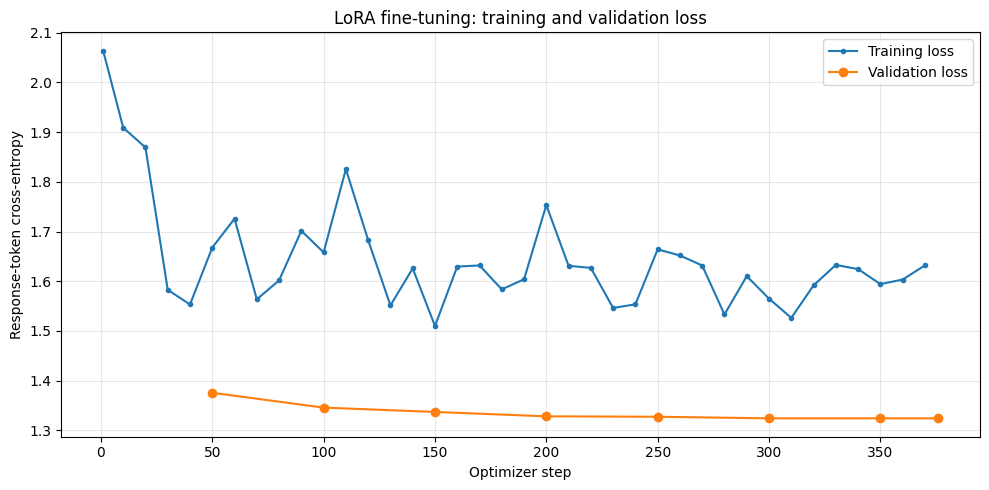

Initial validation loss: 1.8756
Final validation loss:   1.3242
Loss change:             -0.5514
Validation loss decreased. Check generated responses next.


In [10]:
history = pd.DataFrame(trainer.state.log_history)
history.to_csv(OUTPUT_DIR / "training_log.csv", index=False)

training_rows = history.dropna(subset=["loss"])
validation_rows = history.dropna(subset=["eval_loss"])

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    training_rows["step"],
    training_rows["loss"],
    marker=".",
    label="Training loss",
)

ax.plot(
    validation_rows["step"],
    validation_rows["eval_loss"],
    marker="o",
    label="Validation loss",
)

ax.set_xlabel("Optimizer step")
ax.set_ylabel("Response-token cross-entropy")
ax.set_title("LoRA fine-tuning: training and validation loss")
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "loss_curve.png", dpi=180)
plt.show()

initial_loss = metrics["initial_validation_loss"]
final_loss = metrics["final_validation_loss"]

print(f"Initial validation loss: {initial_loss:.4f}")
print(f"Final validation loss:   {final_loss:.4f}")
print(f"Loss change:             {final_loss - initial_loss:+.4f}")

if final_loss < initial_loss:
    print("Validation loss decreased. Check generated responses next.")
else:
    print("Validation loss did not decrease; improvement is not established.")

## 11. Persist the adapter and tokenizer

The saved adapter weights occupy 9,034,304 bytes (8.62 MiB); the complete folder occupies 12.56 MiB including tokenizer and supporting files. These are measured sizes from the supplied run, not estimates. The notebook preserves evidence of saving, but embedding notebook outputs does not embed the actual adapter weight files.

In [11]:
ADAPTER_DIR = OUTPUT_DIR / "adapter"

trainer.save_model(str(ADAPTER_DIR))
tokenizer.save_pretrained(ADAPTER_DIR)

adapter_files = list(
    ADAPTER_DIR.glob("adapter_model*.safetensors")
)

assert adapter_files, "No adapter weight file found."

adapter_bytes = sum(
    path.stat().st_size
    for path in adapter_files
)

folder_bytes = sum(
    path.stat().st_size
    for path in ADAPTER_DIR.rglob("*")
    if path.is_file()
)

print(f"Adapter weight size: {adapter_bytes:,} bytes")
print(f"Adapter weight size: {adapter_bytes / 2**20:.2f} MiB")
print(f"Complete saved folder: {folder_bytes / 2**20:.2f} MiB")

metrics["adapter_bytes"] = adapter_bytes

with open(OUTPUT_DIR / "metrics.json", "w") as file:
    json.dump(metrics, file, indent=2)

print("\nSaved files:")
for path in sorted(ADAPTER_DIR.iterdir()):
    print(path.name)

Adapter weight size: 9,034,304 bytes
Adapter weight size: 8.62 MiB
Complete saved folder: 12.56 MiB

Saved files:
README.md
adapter_config.json
adapter_model.safetensors
chat_template.jinja
special_tokens_map.json
tokenizer.json
tokenizer.model
tokenizer_config.json
training_args.bin


## 12. Reload the saved adapter

The trainer and backbone references are released before loading a fresh base model and attaching the saved adapter. The success message records that the saved adapter reloaded in the original runtime. Reopening this notebook alone does not restore /content/lora_results/adapter: rerun training or supply the saved adapter directory.

In [12]:
del trainer, model, base_model

gc.collect()
torch.cuda.empty_cache()

tokenizer = AutoTokenizer.from_pretrained(ADAPTER_DIR)

fresh_base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    revision=MODEL_REVISION,
    torch_dtype=torch.float16,
    attn_implementation="sdpa",
).to("cuda")

fine_tuned_model = PeftModel.from_pretrained(
    fresh_base_model,
    str(ADAPTER_DIR),
    is_trainable=False,
)

fine_tuned_model.config.use_cache = True
fine_tuned_model.eval()

print("Saved adapter successfully reloaded.")

Saved adapter successfully reloaded.


## 13. Compare baseline and fine-tuned responses

All 20 comparisons are retained, including regressions. Examples 5 and 6 show concise context extraction; example 12 gives the requested DC/Marvel mapping without the baseline extra story; example 17 supplies the requested drug/food labels. Regressions remain: example 19 reverses both instrument labels relative to the supplied reference, and examples 7, 9 and 11 contain repetition. These are qualitative observations, not a blinded or independently scored benchmark.

In [13]:
fine_tuned_responses = []

for index, example in enumerate(test_examples, start=1):
    response = generate_response(
        fine_tuned_model,
        example["messages"][:-1],
    )

    fine_tuned_responses.append(response)
    print(f"Fine-tuned {index}/{len(test_examples)} completed")

comparison = pd.DataFrame({
    "prompt": [
        example["messages"][1]["content"]
        for example in test_examples
    ],
    "reference": [
        example["messages"][-1]["content"]
        for example in test_examples
    ],
    "baseline": baseline_responses,
    "fine_tuned": fine_tuned_responses,
})

comparison.to_csv(
    OUTPUT_DIR / "comparison.csv",
    index=False,
)

comparison.to_json(
    OUTPUT_DIR / "comparison.json",
    orient="records",
    indent=2,
)

for index, row in comparison.iterrows():
    print("\n" + "=" * 80)
    print(f"EXAMPLE {index + 1}")
    print("\nPROMPT:\n", row["prompt"])

    display(
        pd.DataFrame({
            "Baseline": [row["baseline"]],
            "Fine-tuned": [row["fine_tuned"]],
        }).style.set_properties(**{
            "white-space": "pre-wrap",
            "text-align": "left",
            "vertical-align": "top",
        })
    )

    print("\nREFERENCE:\n", row["reference"])

Fine-tuned 1/20 completed
Fine-tuned 2/20 completed
Fine-tuned 3/20 completed
Fine-tuned 4/20 completed
Fine-tuned 5/20 completed
Fine-tuned 6/20 completed
Fine-tuned 7/20 completed
Fine-tuned 8/20 completed
Fine-tuned 9/20 completed
Fine-tuned 10/20 completed
Fine-tuned 11/20 completed
Fine-tuned 12/20 completed
Fine-tuned 13/20 completed
Fine-tuned 14/20 completed
Fine-tuned 15/20 completed
Fine-tuned 16/20 completed
Fine-tuned 17/20 completed
Fine-tuned 18/20 completed
Fine-tuned 19/20 completed
Fine-tuned 20/20 completed

EXAMPLE 1

PROMPT:
 Why do Jewish holidays begin at sunset the night before?


,Baseline,Fine-tuned
0,"The Jewish holidays begin at sunset the night before because this is the time when the sun is at its highest point in the sky, which is also the time when the sun is most visible to the naked eye. This is also the time when the moon is at its fullest, which is why the Jewish calendar is based on lunar cycles. Therefore, the Jewish holidays begin at sunset the night before to ensure that the full moon is visible to the Jewish community.","The Jewish holidays are based on the lunar calendar, which is based on the moon's phase. The moon is full at the beginning of the month, and the full moon is the first day of the month. The Jewish holidays are based on the lunar calendar, so they begin at sunset the night before."



REFERENCE:
 In many modern cultures and calendars, days begin in the morning and end at night.  But what if the opposite were true?   In the opening lines of the Creation story in the book of Genesis, the foundational story for all Abrahamic cultures, we learn that all the world was darkness and void.  (Darkness came first.) And then God said "Let there be light."  (Light came second.)  "And there was evening, and there was morning—the first day." 

This last sentence is critical. The first day consists of evening followed by morning. The Jewish calendar abides by this tradition.  Its days are not morning to morning. Its days are night to night (as marked by sundown).  

As an example, the Jewish sabbath (Shabbat) is on the 7th day of the week. Shabbat = Shevat in Hebrew, which literally translates to the number seven.  The seventh day of the  week is is Saturday. However, Shabbat doesn't span Saturday morning to Sunday morning. It spans Friday night to Saturday night.  Many observant

,Baseline,Fine-tuned
0,"Malanów is located approximately 2 kilometers (1 mile) north of Zygmuntówek, which is located 10 kilometers (6 miles) south-west of Turek and 112 kilometers (70 miles) south-east of the regional capital Poznań.",North-South



REFERENCE:
 Malanów is south of Zygmuntówek. We know this because Zygmuntówek is north of Malanów.

EXAMPLE 3

PROMPT:
 Write an email to a landlord asking to replace a kitchen sink


,Baseline,Fine-tuned
0,"Subject: Request for Replacement of Kitchen Sink Dear [Landlord's Name], I hope this email finds you well. I am writing to request your assistance in replacing the kitchen sink that has been damaged and is no longer functioning properly. As you may know, the sink is located in the kitchen and is used for preparing food and cleaning utensils. The sink has been damaged due to water leaks, which have caused the sink to become clogged and difficult to clean. The sink has also become discolored and has lost its original shine. I understand that this is a significant issue that requires immediate attention. Therefore, I would appreciate it if you could arrange for the replacement of the sink as soon as possible. I have attached a photo of the damaged sink, which you can use as a reference. I am willing","Dear [Landlord's Name], I am writing to request that you replace the kitchen sink that is currently in my apartment. The sink has been leaking for a few weeks and has caused a lot of damage to my kitchen. I have tried to fix the sink myself, but it has not worked. I have also tried to contact the landlord, but they have not responded to my requests. I am worried about the safety of my kitchen and the damage that the sink has caused. I would appreciate it if you could replace the sink as soon as possible. I am willing to pay for the replacement, but I would prefer to do it myself if possible. Thank you for your attention to this matter. I look forward to hearing from you soon. Best regards, [Your Name]"


... (31 outputs left out)

,Baseline,Fine-tuned
0,"The Koto is a string instrument that is played by plucking the strings with the fingers or a plectrum. It is a type of Japanese zither, and it is often used in traditional Japanese music. The Koto is not a woodwind instrument, as it does not produce sound through the expansion of air.","Soprillo is string, Koto is woodwind."



REFERENCE:
 Koto is string, Soprillo is woodwind.

EXAMPLE 20

PROMPT:
 Can you recommend 3 diverse National Parks in California worth a visit?


,Baseline,Fine-tuned
0,"Certainly! Here are three diverse National Parks in California that are worth a visit: 1. Yosemite National Park: Located in the Sierra Nevada Mountains, Yosemite is a stunning park with stunning waterfalls, glaciers, and diverse wildlife. It's a great place to hike, camp, and explore the natural beauty of the park. 2. Joshua Tree National Park: Located in Southern California, Joshua Tree is a unique desert landscape with towering rock formations, colorful sand dunes, and a variety of wildlife. It's a great place to explore the desert and enjoy the natural beauty of the park. 3. Sequoia & Kings Canyon National Parks: Located in the Sierra Nevada Mountains, Sequoia & Kings Canyon are two of the largest and most diverse national par","Yes, there are three National Parks in California that are diverse and worth a visit. 1. Yosemite National Park - This park is known for its stunning waterfalls, hiking trails, and scenic views. 2. Joshua Tree National Park - This park is known for its unique rock formations, desert landscapes, and wildlife. 3. Death Valley National Park - This park is known for its extreme temperatures, rock formations, and unique wildlife."



REFERENCE:
 California is home to several top tier National Parks. Yosemite would be at top of many lists for its natural beauty, including granite formations like Half Dome and El Capitan, lofty waterfalls like Yosemite and Bridalveil and distinctive landscapes like Tuolumne Meadows and the Mariposa Grove of giant sequoias. Lassen National Park is hidden gem in the northeast corner of the state. One can day hike to the top of the namesake volcano and explore active signs of vulcanism such as the fumaroles and mudpots of Bumpass Hell. Joshua Tree National Park, in the southeast part of the state, is fairly distinct from both Yosemite and Lassen with desert flora and fauna, include the namesake tree which is actually a succulent.


## Analysis and conclusion

### Measured efficiency and training results

| Metric | Recorded result |
| --- | --- |
| GPU | Tesla T4 |
| Base parameters | 1,100,048,384 |
| Trainable adapter parameters | 2,252,800 |
| Total parameters with LoRA | 1,102,301,184 |
| Trainable share | 0.2044% |
| Adapter weight size | 9,034,304 bytes / 8.62 MiB |
| Initial validation loss | 1.8755555 |
| Final validation loss | 1.3242002 |
| Relative validation loss reduction | approximately 29.4% |
| Optimizer steps / epochs | 376 / 2 |
| Selected checkpoint | 350 |
| Training runtime | 1,881.10 seconds / 31.35 minutes |
| Peak PyTorch allocated GPU memory | 2.3306 GiB |

### What improved

The fine-tuned model often responds more directly to short extraction and classification requests. For the pickleball question (example 5), it returns `1965`, matching the supplied context, whereas the baseline adds an unsupported 1962 claim. For the DC/Marvel question (example 12), it supplies the requested mapping without the baseline's additional character story. For example 17, it explicitly labels all six items rather than repeating them without classifications.

### What did not improve

The instrument classification in example 19 is reversed relative to the reference. The movie list, martial-arts response and car-buying response (examples 7, 9 and 11) exhibit substantial repetition. The geographical answer in example 2 becomes the ambiguous `North-South`. Conciseness by itself is not correctness, and a lower validation loss does not guarantee better instruction following on every prompt.

### Evaluation scope

The notebook contains 20 paired outputs, but no completed numerical human-scoring sheet. Win/tie/loss totals and 0–2 rubric scores are therefore not claimed. A follow-up evaluation should score instruction compliance, contextual correctness and relevance across the full panel, ideally with model identities hidden. After tuning on validation data, use a new untouched test panel for the final assessment.

### Conclusion and limitations

The run demonstrates parameter-efficient training, lower held-out response-token loss, adapter persistence and successful reload. Qualitative results are mixed: several short answers improve, while repetition and classification errors remain. The evidence supports selective improvements, not a universal quality gain or production readiness.

The experiment uses a 3,000-example general-purpose training subset, a 512-token length filter and only 20 qualitative test examples. Exact deduplication does not remove semantic near-duplicates. Dataset references can themselves contain errors; they are useful guides rather than an infallible answer key. The initial environment has recorded dependency warnings, so a clean rerun should verify dependency compatibility separately.
